In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.transforms as mtransforms
from matplotlib.lines import Line2D

from plot_style import C, apply

FIG = Path("figs")
DATA = FIG / "data"
OUTPUT = FIG / "Fig9.pdf"
DEST_SYNC = 0
DEST_CLUSTER = 1

apply()

heterogeneity_data = np.load(DATA / "saddle_outflow_two_perturbations.npz")
edge_deletion_data = np.load(DATA / "three_triangles_lower_edge_deletion.npz")
random_embedding_data = np.load(DATA / "random_simplicial_embedding_production.npz")

In [2]:
def panel_label(ax, label, dx_pt=-12.0, dy_pt=4.0, fontsize=8.6):
    transform = ax.transAxes + mtransforms.ScaledTranslation(
        dx_pt / 72.0, dy_pt / 72.0, ax.figure.dpi_scale_trans
    )
    ax.text(
        0.0, 1.0, label, transform=transform, ha="left", va="bottom",
        fontsize=fontsize, fontweight="bold", color="#222222",
        clip_on=False, zorder=30,
    )


def clean(ax):
    ax.grid(True, alpha=0.35, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(which="both", top=False, right=False)
    for s in ("left", "bottom"):
        ax.spines[s].set_color("0.3")


def conditional_quantiles(values, saddle_mask):
    lower = np.full(values.shape[1], np.nan)
    median = np.full(values.shape[1], np.nan)
    upper = np.full(values.shape[1], np.nan)

    for index in range(values.shape[1]):
        selected = values[:, index][saddle_mask[:, index]]
        if selected.size:
            lower[index], median[index], upper[index] = np.quantile(
                selected, (0.25, 0.50, 0.75)
            )

    return lower, median, upper

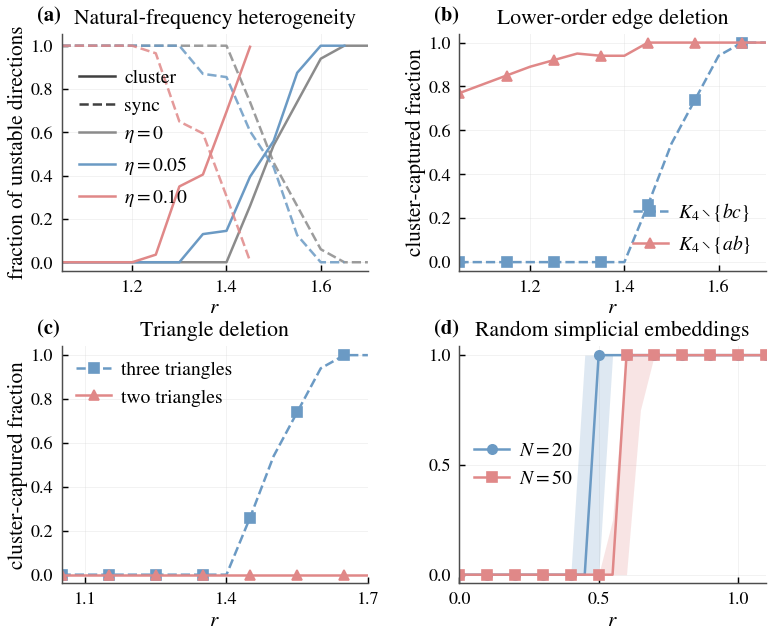

In [3]:
TICK_FONT_SIZE = 8.7
AXIS_LABEL_FONT_SIZE = 10.2
TITLE_FONT_SIZE = 10.4
LEGEND_FONT_SIZE = 9.4
PANEL_LABEL_FONT_SIZE = 9.8
LINE_WIDTH = 1.2
MARKER_SIZE = 4.5

fig, axes = plt.subplots(2, 2, figsize=(5.08, 4.18))
fig.subplots_adjust(wspace=0.4, hspace=0.25)

ax_a = axes[1, 0]
ax_b = axes[0, 0]
ax_c = axes[0, 1]
ax_d = axes[1, 1]

r = heterogeneity_data["r"]
triangle_styles = (
    (heterogeneity_data["h_eta0_fractions"][:, DEST_CLUSTER], C["blue"], "s", "--",
     "three triangles"),
    (heterogeneity_data["s_c2_b_fractions"][:, DEST_CLUSTER], C["red"], "^", "-",
     "two triangles"),
)
for fraction, color, marker, linestyle, label in triangle_styles:
    ax_a.plot(
        r, fraction, color=color, marker=marker, linestyle=linestyle,
        linewidth=LINE_WIDTH, markevery=2, markersize=MARKER_SIZE,
        label=label,
    )
ax_a.set_title("Triangle deletion", fontsize=TITLE_FONT_SIZE, pad=5.0)
ax_a.set_xlabel(r"$r$", fontsize=AXIS_LABEL_FONT_SIZE)
ax_a.set_ylabel("cluster-captured fraction", fontsize=AXIS_LABEL_FONT_SIZE)
ax_a.set_xlim(r[0], r[-1])
ax_a.set_ylim(-0.04, 1.04)
ax_a.set_xticks([1.1, 1.4, 1.7])
ax_a.set_yticks(np.linspace(0.0, 1.0, 6))
ax_a.legend(loc="upper left", fontsize=LEGEND_FONT_SIZE, frameon=False)
clean(ax_a)

eta_styles = (
    ("h_eta0", C["gray"], r"$\eta=0$"),
    ("h_eta005", C["blue"], r"$\eta=0.05$"),
    ("h_eta010", C["red"], r"$\eta=0.10$"),
)
for key, color, label in eta_styles:
    fractions = heterogeneity_data[f"{key}_fractions"]
    ax_b.plot(r, fractions[:, DEST_CLUSTER], color=color, linestyle="-",
              linewidth=LINE_WIDTH)
    ax_b.plot(r, fractions[:, DEST_SYNC], color=color, linestyle="--",
              linewidth=LINE_WIDTH, alpha=0.85)

routing_handles = [
    Line2D([0], [0], color="0.25", linestyle="-", linewidth=LINE_WIDTH, label="cluster"),
    Line2D([0], [0], color="0.25", linestyle="--", linewidth=LINE_WIDTH, label="sync"),
]
parameter_handles = [
    Line2D([0], [0], color=color, linestyle="-", linewidth=LINE_WIDTH, label=label)
    for _, color, label in eta_styles
]
ax_b.set_title("Natural-frequency heterogeneity", fontsize=TITLE_FONT_SIZE, pad=5.0)
ax_b.set_xlabel(r"$r$", fontsize=AXIS_LABEL_FONT_SIZE)
ax_b.set_ylabel("fraction of unstable directions", fontsize=AXIS_LABEL_FONT_SIZE)
ax_b.set_xlim(r[0], r[-1])
ax_b.set_ylim(-0.04, 1.055)
ax_b.set_yticks(np.linspace(0.0, 1.0, 6))
ax_b.legend(
    handles=routing_handles + parameter_handles,
    fontsize=LEGEND_FONT_SIZE,
    loc="lower left",
    bbox_to_anchor=(0.01, 0.2),
    frameon=False,
)
clean(ax_b)

r = edge_deletion_data["r"]
edge_styles = (
    ("minus_bc", C["blue"], "s", "--", r"$K_4\setminus\{bc\}$"),
    ("minus_ab", C["red"], "^", "-", r"$K_4\setminus\{ab\}$"),
)
for key, color, marker, linestyle, label in edge_styles:
    ax_c.plot(
        r, edge_deletion_data[f"{key}_fractions"][:, DEST_CLUSTER],
        color=color, marker=marker, linestyle=linestyle,
        linewidth=LINE_WIDTH, markevery=2, markersize=MARKER_SIZE,
        label=label,
    )
ax_c.set_title("Lower-order edge deletion", fontsize=TITLE_FONT_SIZE, pad=5.0)
ax_c.set_xlabel(r"$r$", fontsize=AXIS_LABEL_FONT_SIZE)
ax_c.set_ylabel("cluster-captured fraction", fontsize=AXIS_LABEL_FONT_SIZE)
ax_c.set_xlim(r[0], r[-1])
ax_c.set_ylim(-0.04, 1.04)
ax_c.set_yticks(np.linspace(0.0, 1.0, 6))
ax_c.legend(fontsize=LEGEND_FONT_SIZE, loc="lower right", frameon=False)
clean(ax_c)

r = random_embedding_data["r_values"]
network_styles = ((20, C["blue"], "o"), (50, C["red"], "s"))
for n, color, marker in network_styles:
    saddle_mask = random_embedding_data[f"is_saddle_n{n}"]
    cluster_values = random_embedding_data[f"fractions_n{n}"][:, :, DEST_CLUSTER]
    lower, median, upper = conditional_quantiles(cluster_values, saddle_mask)
    ax_d.fill_between(r, lower, upper, color=color, alpha=0.22, linewidth=0)
    ax_d.plot(
        r, median, color=color, marker=marker, markevery=2,
        markersize=MARKER_SIZE, linewidth=LINE_WIDTH, label=rf"$N={n}$",
    )
ax_d.set_title("Random simplicial embeddings", fontsize=TITLE_FONT_SIZE, pad=5.0)
ax_d.set_xlabel(r"$r$", fontsize=AXIS_LABEL_FONT_SIZE)
ax_d.set_xlim(r[0], 1.1)
ax_d.set_xticks((0.0, 0.5, 1.0))
ax_d.set_ylim(-0.04, 1.04)
ax_d.set_yticks((0.0, 0.5, 1.0))
ax_d.legend(fontsize=LEGEND_FONT_SIZE, loc="center left", frameon=False)
clean(ax_d)

for index, axis in enumerate(axes.flat):
    axis.tick_params(axis="both", direction="in", labelsize=TICK_FONT_SIZE, pad=4.0)
    axis.xaxis.labelpad = 1.4
    axis.yaxis.labelpad = 1.4
    panel_label(axis, f"({chr(97 + index)})", fontsize=PANEL_LABEL_FONT_SIZE)
    axis.texts[-1].set_color("black")

fig.tight_layout(pad=0.10, w_pad=2)
fig.savefig(OUTPUT)
plt.show()